# LAB 05 — Sequence Models: RNN / LSTM / GRU trên IMDb
Raw text → tokenizer → token IDs → padding/truncation → embedding → RNN/LSTM/GRU → linear → sentiment.

**Cách chạy:** các mô hình sequence được huấn luyện trên **Kaggle (GPU)** với **toàn bộ** dữ liệu của cách chia 60/20/20 (seed 2026) giống LAB 04: train 29,746 / val 9,916 / test 9,916. Kết quả huấn luyện từng cấu hình được lưu trong `cache/`; chạy lại notebook ở máy local sẽ nạp cache thay vì train lại (xóa `cache/` để train lại từ đầu). Embedding 100, hidden 128.

In [1]:
import sys, os, time, csv, pickle, random, warnings
from collections import Counter
sys.path.insert(0, "../lab04")                       # dùng lại preprocessing của LAB 04 (cùng split)
import numpy as np, pandas as pd, psutil
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import preprocessing as pp
from rnn_cell import SimpleRNNCell
warnings.filterwarnings("ignore")
SEED = 2026
torch.set_num_threads(8)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
RESULTS = []
def log(exp, cfg, metric, val): RESULTS.append((exp, cfg, metric, val))
os.makedirs("cache", exist_ok=True)

## Experiment 1 — Dataset inspection (độ dài sequence)

n_samples          50000
n_classes          2
class_counts       {'positive': 25000, 'negative': 25000}
duplicate_reviews  418
missing_text       0
missing_label      0


count    49578.0
mean       229.9
std        170.3
min          6.0
50%        172.0
75%        279.0
90%        449.0
95%        587.0
max       2462.0
min / median / mean / max token length: 6 172.0 229.9 2462


,pct_reviews_fully_kept,pct_tokens_retained
max_length,,
30,0.2,13.0
50,2.5,21.7
100,12.6,41.8
200,59.4,68.9
300,78.0,82.0
400,87.2,89.4


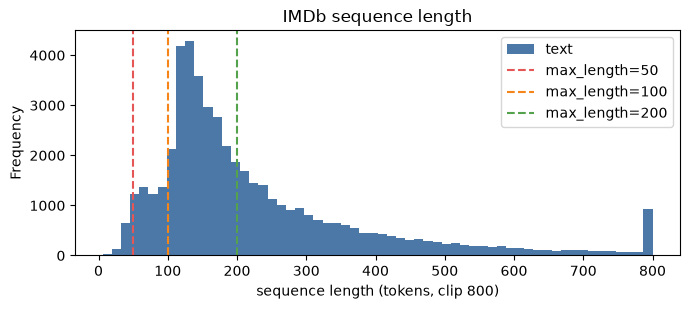

In [2]:
raw = pp.load_imdb()
info = pp.inspect(raw)
for k in ("n_samples","n_classes","class_counts","duplicate_reviews","missing_text","missing_label"): print(f"{k:18s}", info[k])
data = pp.prepare(raw)                                 # bỏ HTML, bỏ trùng, nhãn 0/1
tok_len = data.text.map(lambda t: len(pp.tokenize(t)))
stat = tok_len.describe(percentiles=[.5,.75,.9,.95]).round(1); print(stat.to_string())
print("min / median / mean / max token length:", tok_len.min(), tok_len.median(), round(tok_len.mean(),1), tok_len.max())
rows = []
for L in (30, 50, 100, 200, 300, 400):
    rows.append(dict(max_length=L, pct_reviews_fully_kept=round((tok_len<=L).mean()*100,1),
                     pct_tokens_retained=round(np.minimum(tok_len, L).sum()/tok_len.sum()*100,1)))
display(pd.DataFrame(rows).set_index("max_length"))
fig, ax = plt.subplots(figsize=(7,3.2)); tok_len.clip(upper=800).plot.hist(bins=60, ax=ax, color="#4c78a8")
for L, c in ((50,"#e45756"),(100,"#f58518"),(200,"#54a24b")): ax.axvline(L, color=c, ls="--", label=f"max_length={L}")
ax.set_xlabel("sequence length (tokens, clip 800)"); ax.set_title("IMDb sequence length"); ax.legend(); plt.tight_layout(); plt.show()
for k, v in (("samples", info["n_samples"]), ("duplicates", info["duplicate_reviews"]), ("min_len", int(tok_len.min())),
             ("median_len", float(tok_len.median())), ("mean_len", round(float(tok_len.mean()),1)), ("max_len", int(tok_len.max()))):
    log("exp1_dataset", "imdb", k, v)

**Nếu phải chọn `max_length`, nên dựa vào thông tin nào?** Dựa vào *phân phối độ dài* và *lượng thông tin giữ lại*, không dựa vào tốc độ: trung vị 172 token, trung bình 230, p90 = 449, max 2,462. Với `max_length = 200` chỉ 59.4% review được giữ nguyên và 68.9% tổng số token còn lại; với 100 chỉ còn 41.8% token, với 50 chỉ 21.7%. Chi phí tính toán tỉ lệ thuận với độ dài, nên ta chọn điểm mà phần trăm token giữ lại đã cao nhưng chi phí còn chấp nhận được (200 ≈ trung vị + 15%; 300–400 giữ thêm 13–20% token nhưng chi phí cao hơn nhiều). Lưu ý: ta cắt phần **đuôi** (giữ token đầu), mà kết luận/đánh giá của review thường nằm cuối, nên truncation có thể làm mất chính phần quyết định sentiment.

## Chia dữ liệu, tokenizer và vocabulary
Split 60/20/20 stratified, seed 2026 (giống LAB 04). Vocabulary chỉ xây từ **train**.

In [3]:
train_full, val_full, test_full = pp.split(data)
def sub(df, n): return df.reset_index(drop=True) if n is None else pd.concat([df[df.label==k].sample(n//2, random_state=SEED) for k in (0,1)]).sample(frac=1, random_state=SEED).reset_index(drop=True)
N_TRAIN = N_VAL = N_TEST = None                      # None = dùng toàn bộ split
train, val, test = sub(train_full, N_TRAIN), sub(val_full, N_VAL), sub(test_full, N_TEST)
print("train/val/test:", len(train), len(val), len(test), "| positive rate:", [round(d.label.mean(),3) for d in (train,val,test)])
cnt = Counter(w for t in train.text for w in pp.tokenize(t))
itos = ["<pad>", "<unk>"] + [w for w, c in cnt.most_common() if c >= 3][:19998]     # PAD = 0, UNK = 1
stoi = {w: i for i, w in enumerate(itos)}
print("vocabulary size:", len(itos), "| tokens covered:", round(sum(c for w,c in cnt.items() if w in stoi)/sum(cnt.values())*100,1), "%")
ex = "I really like this movie"
ids = [stoi.get(w, 1) for w in pp.tokenize(ex)]; print(ex, "->", ids, "-> sau padding (len 8):", ids + [0]*(8-len(ids)))
def encode(texts, L):
    """Cắt tail (giữ L token đầu) và pad bên phải bằng 0. Trả về (ids, độ dài thật sau khi cắt)."""
    rows, lens = [], []
    for t in texts:
        ids = [stoi.get(w, 1) for w in pp.tokenize(t)][:L] or [1]
        lens.append(len(ids)); rows.append(ids + [0]*(L-len(ids)))
    return torch.tensor(rows), torch.tensor(lens)

train/val/test: 29746 9916 9916 | positive rate: [np.float64(0.502), np.float64(0.502), np.float64(0.502)]


vocabulary size: 20000 | tokens covered: 97.3 %
I really like this movie -> [10, 61, 37, 11, 17] -> sau padding (len 8): [10, 61, 37, 11, 17, 0, 0, 0]


**Padding vs truncation:** *truncation* cắt bỏ phần token vượt quá `max_length` (mất thông tin thật); *padding* chỉ thêm `<pad>` (id 0) cho đủ độ dài, **không phải thông tin ngôn ngữ**. Để PAD không làm nhiễu hidden state, model dùng `pack_padded_sequence` nên RNN chỉ đọc đến token thật cuối cùng.

## Core implementation — SimpleRNNCell (`rnn_cell.py`)

In [4]:
import rnn_cell
rnn_cell._tests()                                      # khớp Bài 1 (tính tay) và khớp torch.nn.RNNCell
cell = SimpleRNNCell(2, 2)
cell.W_xh = np.array([[0.5, 0.2],[0.1, 0.4]]); cell.W_hh = np.array([[0.3, 0.1],[0.2, 0.5]]); cell.b_h = np.zeros(2)
x_t, h_prev = np.array([1.0, 0.0]), np.array([0.5, 0.2])
print("a_t = W_xh x_t + W_hh h_prev =", cell.W_xh @ x_t + cell.W_hh @ h_prev)
print("h_t = tanh(a_t) =", cell.forward(x_t, h_prev).round(3))
d = SimpleRNNCell(3, 4, seed=1); dog, bites, man = np.eye(3)
print("dog bites man vs man bites dog khác nhau:", not np.allclose(d.forward_sequence([dog,bites,man])[-1], d.forward_sequence([man,bites,dog])[-1]))

all tests passed
a_t = W_xh x_t + W_hh h_prev = [0.67 0.3 ]
h_t = tanh(a_t) = [0.585 0.291]
dog bites man vs man bites dog khác nhau: True


**Giải thích computation graph:** tại mỗi timestep, input xₜ đi qua Wₓₕ và hidden cũ hₜ₋₁ đi qua Wₕₕ; hai nhánh được **cộng** (cùng bias bₕ) rồi qua **tanh** để ra hₜ. Cùng một bộ trọng số (Wₓₕ, Wₕₕ, bₕ) được dùng lại ở mọi timestep; hₜ vừa là output vừa là input của bước sau, nên hₜ mang thông tin của mọi token trước đó. Kết quả cell tự viết khớp tính tay (hₜ ≈ [0.585, 0.291]) và khớp `torch.nn.RNNCell` khi chép cùng trọng số.

## Mô hình và vòng huấn luyện
Cùng điều kiện cho mọi model: embedding 100, hidden 128, dropout 0.3, Adam lr 2e-3, batch 64, 8 epoch, gradient clipping 1.0, chọn epoch có validation loss thấp nhất. Chỉ thay kiến trúc recurrent.

In [5]:
EPOCHS, BATCH, LR = 8, 64, 2e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:", DEVICE)
class SeqClassifier(nn.Module):
    def __init__(self, arch, vocab, emb=100, hid=128, drop=0.3):
        super().__init__()
        self.arch = arch
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[arch](emb, hid, batch_first=True)
        self.drop, self.fc = nn.Dropout(drop), nn.Linear(hid, 1)
    def forward(self, x, lens):
        p = nn.utils.rnn.pack_padded_sequence(self.emb(x), lens, batch_first=True, enforce_sorted=False)
        _, h = self.rnn(p); h = h[0] if self.arch == "LSTM" else h       # LSTM trả (h, c)
        return self.fc(self.drop(h[-1])).squeeze(-1)                     # logit
def n_params(m): return sum(p.numel() for p in m.parameters())
lossf = nn.BCEWithLogitsLoss()
@torch.no_grad()
def predict(model, X, lens, bs=256):
    model.eval(); dev = next(model.parameters()).device; out = []
    for i in range(0, len(X), bs): out.append(torch.sigmoid(model(X[i:i+bs].to(dev), lens[i:i+bs])).cpu())
    return torch.cat(out).numpy()
def metrics(y, p, thr=0.5):
    q = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(y,q), precision=precision_score(y,q), recall=recall_score(y,q), f1=f1_score(y,q))
def train_run(arch, L, epochs=EPOCHS):
    """Huấn luyện (hoặc nạp cache) một cấu hình. Cache trong .cache/ để chạy lại notebook không phải train lại."""
    path = f"cache/{arch}_{L}.pt"
    if os.path.exists(path): return torch.load(path, map_location="cpu", weights_only=False)
    torch.manual_seed(SEED); np.random.seed(SEED)
    Xtr, ltr = encode(train.text, L); Xva, lva = encode(val.text, L); Xte, lte = encode(test.text, L)
    Xtr = Xtr.to(DEVICE); ytr = torch.tensor(train.label.values, dtype=torch.float32, device=DEVICE); yva = val.label.values
    model = SeqClassifier(arch, len(itos)).to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    proc = psutil.Process(); rss0 = proc.memory_info().rss; peak = rss0
    hist = dict(train_loss=[], val_loss=[], epoch_s=[]); best = (1e9, None, 0); t_total = 0.0
    for ep in range(epochs):
        model.train(); t0 = time.time(); perm = torch.randperm(len(Xtr)); tl = 0.0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i+BATCH]
            idd = idx.to(DEVICE); loss = lossf(model(Xtr[idd], ltr[idx]), ytr[idd])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item() * len(idx); peak = max(peak, proc.memory_info().rss)
        pv = predict(model, Xva, lva)
        vl = float(lossf(torch.logit(torch.tensor(pv).clamp(1e-6, 1-1e-6)), torch.tensor(yva, dtype=torch.float32)))
        dt = time.time() - t0; t_total += dt
        hist["train_loss"].append(tl/len(Xtr)); hist["val_loss"].append(vl); hist["epoch_s"].append(dt)
        if vl < best[0]: best = (vl, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep + 1)
        with open("train_log.txt", "a", encoding="utf8") as f:
            f.write(f"{arch} L={L} ep{ep+1}: train {tl/len(Xtr):.4f} val {vl:.4f} val_acc {((pv>=.5)==yva).mean():.3f} {dt:.0f}s\n")
    model.load_state_dict(best[1]); model = model.to(DEVICE); pt = predict(model, Xte, lte)
    res = dict(arch=arch, L=L, hist=hist, best_epoch=best[2], epochs=epochs, train_time=t_total, params=n_params(model),
               peak_mem_mb=(torch.cuda.max_memory_allocated()/1e6 if DEVICE.type=="cuda" else (peak-rss0)/1e6), test_probs=pt, test_metrics=metrics(test.label.values, pt), state=best[1],
               val_probs=predict(model, Xva, lva), tokens_retained=float((np.minimum(lte.numpy(), L)).sum()))
    torch.save(res, path); return res

device: cpu


## Experiment 3 — Baseline TF-IDF + Logistic Regression (từ LAB 04) vs RNN + Embedding

In [6]:
def tfidf_baseline(tr):
    t0 = time.time(); v = TfidfVectorizer(min_df=2, sublinear_tf=True); A = v.fit_transform(tr.text)
    m = LogisticRegression(C=3, max_iter=2000).fit(A, tr.label); tt = time.time() - t0
    p = m.predict_proba(v.transform(test.text))[:,1]; return metrics(test.label.values, p), tt, p, (v, m)
base_sub, t_sub, p_base, base_obj = tfidf_baseline(train)          # baseline LAB 04 (cùng split)
rnn200 = train_run("RNN", 200)
cmp3 = pd.DataFrame([
    dict(Model="Logistic Regression", Representation="TF-IDF", **base_sub, train_time_s=t_sub),
    dict(Model="RNN", Representation="Embedding (L=200)", **rnn200["test_metrics"], train_time_s=rnn200["train_time"])]).round(4)
display(cmp3)
for _, r in cmp3.iterrows():
    for k in ("accuracy","precision","recall","f1","train_time_s"): log("exp3_baseline", f"{r.Model}|{r.Representation}", k, r[k])

,Model,Representation,accuracy,precision,recall,f1,train_time_s
0,Logistic Regression,TF-IDF,0.9063,0.9002,0.9148,0.9074,5.1997
1,RNN,Embedding (L=200),0.7301,0.6985,0.8133,0.7516,45.1188


**RNN có thực sự dùng thông tin sequence mà TF-IDF không dùng không?** Chỉ so sánh accuracy thì **không có bằng chứng**: RNN (acc 0.730, F1 0.752) kém xa TF-IDF + LR (acc 0.906, F1 0.907), vì RNN được huấn luyện từ đầu (embedding ngẫu nhiên, 8 epoch) còn TF-IDF dùng trực tiếp trọng số từng từ. Bằng chứng rằng RNN *có* dùng thứ tự đến từ Experiment 6: dự đoán của RNN thay đổi hẳn theo **vị trí** của từ quyết định (margin ≈ 0 khi ở đầu/giữa, 0.70 khi ở cuối), điều mà TF-IDF (bag-of-words, không có thứ tự) không thể làm. Tức là RNN dùng thông tin vị trí, nhưng dùng chưa hiệu quả bằng baseline từ vựng trên dữ liệu này.

## Experiment 4 — RNN vs LSTM vs GRU (cùng điều kiện, max_length = 200)

In [7]:
runs200 = {a: train_run(a, 200) for a in ("RNN", "LSTM", "GRU")}
tab4 = pd.DataFrame([dict(Model=a, Parameters=r["params"], Training_time_s=round(r["train_time"],1), Epochs=r["epochs"], Best_epoch=r["best_epoch"],
                           **{k: round(v,4) for k, v in r["test_metrics"].items()}, Peak_mem_MB=round(r["peak_mem_mb"])) for a, r in runs200.items()]).set_index("Model")
display(tab4)
for a, r in runs200.items():
    for k, v in r["test_metrics"].items(): log("exp4_rnn_lstm_gru", a, k, round(v,4))
    log("exp4_rnn_lstm_gru", a, "params", r["params"]); log("exp4_rnn_lstm_gru", a, "train_time_s", round(r["train_time"],1)); log("exp4_rnn_lstm_gru", a, "best_epoch", r["best_epoch"])
print("vocabulary size:", len(itos), "| sequence length: 200 | epochs tối đa:", EPOCHS)

,Parameters,Training_time_s,Epochs,Best_epoch,accuracy,precision,recall,f1,Peak_mem_MB
Model,,,,,,,,,
RNN,2029569,45.1,8,6,0.7301,0.6985,0.8133,0.7516,167
LSTM,2117889,48.2,8,4,0.8543,0.8538,0.8563,0.8551,235
GRU,2088449,46.6,8,3,0.8787,0.8788,0.8796,0.8792,212


vocabulary size: 20000 | sequence length: 200 | epochs tối đa: 8


**Kết quả có phù hợp prediction không?** Phần lớn có (xem `prediction.md`): LSTM tốt hơn RNN rõ rệt (F1 0.855 so với 0.752), đúng Prediction 2. GRU còn tốt hơn LSTM (F1 0.879), điều không dự đoán trước nhưng phù hợp với việc GRU đơn giản hơn nên dễ tối ưu hơn trên dữ liệu vừa. Không kết luận chỉ bằng accuracy: RNN có precision 0.699 nhưng recall 0.813 (dự đoán positive quá nhiều, FP = 1,747), trong khi LSTM/GRU cân bằng (precision ≈ recall). Tham số: ~2.0–2.1M, trong đó 2.0M là embedding (20,000 × 100); phần recurrent chỉ 29,440 (RNN), 117,760 (LSTM, ×4 vì 4 khối) và 88,320 (GRU, ×3). Thời gian train gần như bằng nhau (45–48 s trên GPU Kaggle) nên chi phí không phải yếu tố phân biệt ở quy mô này. Đây là kết quả của **một seed, một dataset** nên không thể khẳng định LSTM/GRU luôn hơn RNN (Prediction 5).

## Learning curves

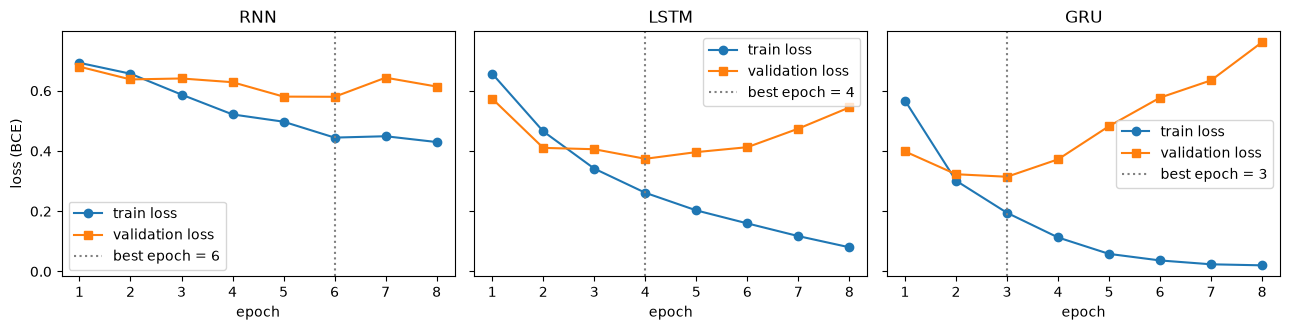

RNN


Epoch,1,2,3,4,5,6,7,8
Train Loss,0.6927,0.6566,0.5873,0.5214,0.4973,0.4445,0.4490,0.4297
Validation Loss,0.6800,0.6376,0.6408,0.6284,0.5805,0.5800,0.6435,0.6140


LSTM


Epoch,1,2,3,4,5,6,7,8
Train Loss,0.6566,0.4652,0.3415,0.2612,0.2028,0.1595,0.1173,0.0802
Validation Loss,0.5736,0.4103,0.4059,0.3741,0.3963,0.4126,0.4743,0.5447


GRU


Epoch,1,2,3,4,5,6,7,8
Train Loss,0.5676,0.3015,0.1947,0.1129,0.0583,0.0365,0.0237,0.0203
Validation Loss,0.3985,0.3228,0.3144,0.3723,0.4826,0.5772,0.6347,0.7614


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (a, r) in zip(axes, runs200.items()):
    e = range(1, len(r["hist"]["train_loss"])+1)
    ax.plot(e, r["hist"]["train_loss"], "o-", label="train loss"); ax.plot(e, r["hist"]["val_loss"], "s-", label="validation loss")
    ax.axvline(r["best_epoch"], color="gray", ls=":", label=f"best epoch = {r['best_epoch']}"); ax.set_title(a); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("loss (BCE)"); plt.tight_layout(); plt.savefig("learning_curves.png", dpi=130); plt.show()
for a, r in runs200.items():
    print(a); display(pd.DataFrame({"Epoch": range(1, len(r["hist"]["train_loss"])+1), "Train Loss": np.round(r["hist"]["train_loss"],4), "Validation Loss": np.round(r["hist"]["val_loss"],4)}).set_index("Epoch").T)

**Overfitting?** Có với LSTM và GRU. LSTM: val loss thấp nhất ở epoch 4 (0.374) rồi tăng lên 0.545 ở epoch 8 trong khi train loss giảm xuống 0.080; GRU: val loss thấp nhất ở epoch 3 (0.314), sau đó tăng lên 0.761 khi train loss còn 0.020, dấu hiệu điển hình model bắt đầu overfit (train ↓, val ↑). Lưu ý val *accuracy* gần như không giảm (≈ 0.85–0.865): model vẫn xếp hạng đúng nhưng ngày càng quá tự tin vào dự đoán sai nên loss tăng. Vì vậy ta chọn epoch có val loss thấp nhất (RNN epoch 6, LSTM epoch 4, GRU epoch 3) thay vì epoch cuối. RNN thì khác: train loss 0.43 còn val loss 0.58–0.64 dao động, nghĩa là học chậm và không ổn định hơn là overfit.

## Experiment 2 + 5 — Padding/truncation và sequence length (max_length ∈ {50, 100, 200})
Giữ architecture cố định; chạy cho RNN (theo Prediction 3) và LSTM. Bảng dưới cũng là kết quả của Experiment 2.

pct_tokens_retained  Training_time_s  min_val_loss  \
Model max_length                                                       
RNN   50                         21.6             20.0        0.5918   
      100                        41.6             27.9        0.6076   
      200                        68.6             45.1        0.5800   
LSTM  50                         21.6             21.9        0.4700   
      100                        41.6             30.7        0.4224   
      200                        68.6             48.2        0.3741   

                  Accuracy      F1  Peak_mem_MB  
Model max_length                                 
RNN   50            0.6899  0.7023           90  
      100           0.7076  0.6971          119  
      200           0.7301  0.7516          167  
LSTM  50            0.7765  0.7863          112  
      100           0.8290  0.8319          160  
      200           0.8543  0.8551          235

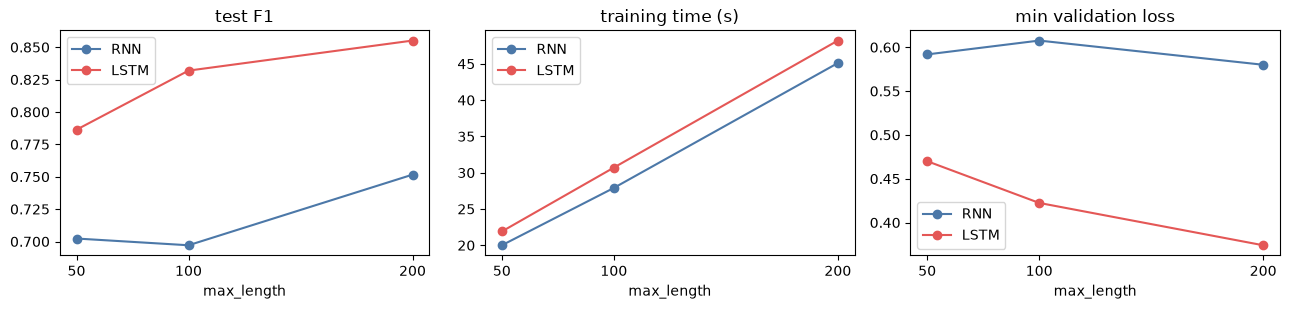

In [9]:
len_runs = {(a, L): train_run(a, L) for a in ("RNN", "LSTM") for L in (50, 100, 200)}
total_tokens = float(sum(len(pp.tokenize(t)) for t in test.text))
rows = []
for (a, L), r in len_runs.items():
    rows.append(dict(Model=a, max_length=L, pct_tokens_retained=round(r["tokens_retained"]/total_tokens*100, 1), Training_time_s=round(r["train_time"],1),
                     min_val_loss=round(min(r["hist"]["val_loss"]),4), Accuracy=round(r["test_metrics"]["accuracy"],4), F1=round(r["test_metrics"]["f1"],4),
                     Peak_mem_MB=round(r["peak_mem_mb"])))
    for k, v in (("accuracy", r["test_metrics"]["accuracy"]), ("f1", r["test_metrics"]["f1"]), ("train_time_s", r["train_time"]), ("min_val_loss", min(r["hist"]["val_loss"]))): log("exp2_5_length", f"{a}|L={L}", k, round(float(v),4))
tab5 = pd.DataFrame(rows); display(tab5.set_index(["Model","max_length"]))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, c in (("RNN","#4c78a8"),("LSTM","#e45756")):
    d = tab5[tab5.Model==a]
    ax[0].plot(d.max_length, d.F1, "o-", color=c, label=a); ax[1].plot(d.max_length, d.Training_time_s, "o-", color=c, label=a); ax[2].plot(d.max_length, d.min_val_loss, "o-", color=c, label=a)
for a_, t in zip(ax, ("test F1", "training time (s)", "min validation loss")): a_.set_xlabel("max_length"); a_.set_title(t); a_.legend(); a_.set_xticks([50,100,200])
plt.tight_layout(); plt.show()

**Có trade-off giữa context và chi phí tính toán không?** Có. Tăng `max_length` từ 50 lên 200 (giữ 21.6% → 68.6% token): LSTM F1 tăng 0.786 → 0.832 → 0.855 và val loss giảm 0.470 → 0.422 → 0.374, nhưng thời gian train tăng 21.9 → 30.7 → 48.2 s và bộ nhớ đỉnh 112 → 160 → 235 MB. Mức tăng F1 giảm dần (+0.046 rồi +0.023) trong khi chi phí tăng đều. Với RNN, tăng độ dài **không luôn cải thiện**: F1 0.702 → 0.697 → 0.752 và val loss 0.592 → 0.608 → 0.580 (không đơn điệu), nhất quán với việc RNN khó dùng context xa (vanishing gradient là giải thích lý thuyết, ở đây ta chỉ có quan sát). Nếu `max_length` quá nhỏ thì mất phần kết luận/đánh giá ở cuối review và các từ tương phản ("but ...").

## Experiment 6 — Long-range dependency (vị trí của từ quyết định sentiment)
Mỗi văn bản gồm 1 câu quyết định sentiment ("..., ultimately excellent/terrible") đặt ở **đầu / giữa / cuối** của một đoạn nền trung tính (8 câu, ≈ 90 token, ≤ 200 nên không bị truncate). Đo P(positive) khi từ quyết định là tích cực và tiêu cực; margin = P(pos | từ tích cực) − P(pos | từ tiêu cực).

trong vocabulary: {'excellent': True, 'wonderful': True, 'superb': True, 'terrible': True, 'awful': True, 'dreadful': True}
độ dài văn bản mẫu ≈ 87 token


P_pos_when_excellent  P_pos_when_terrible  margin
Model position                                                    
RNN   beginning                 0.812                0.812   0.000
      middle                    0.794                0.780   0.013
      end                       0.931                0.233   0.698
LSTM  beginning                 0.936                0.828   0.108
      middle                    0.939                0.823   0.116
      end                       0.988                0.542   0.446
GRU   beginning                 0.956                0.746   0.210
      middle                    0.937                0.738   0.199
      end                       0.931                0.679   0.252

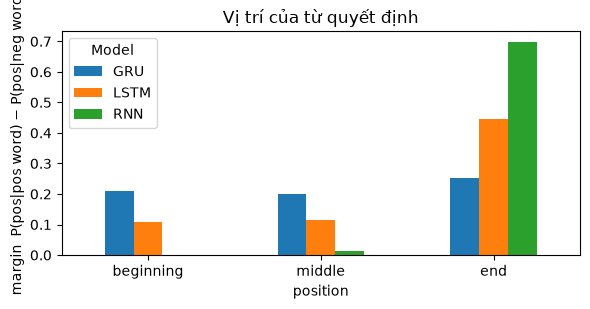

In [10]:
fill = ["the film runs for about two hours and was shot in several cities", "the story follows a family living in a small town",
        "there are many characters and several different locations", "the camera moves slowly through the streets and along the river",
        "the soundtrack uses piano and strings in most scenes", "the cast includes actors from three different countries",
        "the script was written over the course of two years", "the director previously worked on documentaries and short films",
        "the second half takes place during the winter", "the production used both studio sets and real buildings"]
pos_words, neg_words = ["excellent", "wonderful", "superb"], ["terrible", "awful", "dreadful"]
print("trong vocabulary:", {w: w in stoi for w in pos_words + neg_words})
def make(word, where, rng):
    f = rng.sample(fill, 8); key = f"the movie was, despite many unnecessary scenes, ultimately {word}"
    pos = {"beginning": 0, "middle": 4, "end": 8}[where]; parts = f[:pos] + [key] + f[pos:]
    return " . ".join(parts) + " ."
def prob(model, text, L=200):
    X, l = encode([text], L); return float(predict(model, X, l)[0])
def load_model(r):
    m = SeqClassifier(r["arch"], len(itos)); m.load_state_dict(r["state"]); return m.eval()
models200 = {a: load_model(r) for a, r in runs200.items()}
rows = []; ex_len = len(pp.tokenize(make("excellent", "end", random.Random(0))))
print("độ dài văn bản mẫu ≈", ex_len, "token")
for a, m in models200.items():
    for where in ("beginning", "middle", "end"):
        pp_, pn_ = [], []
        for s in range(20):
            for pw, nw in zip(pos_words, neg_words):
                pp_.append(prob(m, make(pw, where, random.Random(s)))); pn_.append(prob(m, make(nw, where, random.Random(s))))
        rows.append(dict(Model=a, position=where, P_pos_when_excellent=round(np.mean(pp_),3), P_pos_when_terrible=round(np.mean(pn_),3), margin=round(np.mean(pp_)-np.mean(pn_),3)))
        log("exp6_position", f"{a}|{where}", "margin", rows[-1]["margin"])
t6 = pd.DataFrame(rows); display(t6.set_index(["Model","position"]))
piv = t6.pivot(index="position", columns="Model", values="margin").loc[["beginning","middle","end"]]
ax = piv.plot.bar(rot=0, figsize=(6,3.2)); ax.set_ylabel("margin  P(pos|pos word) − P(pos|neg word)"); ax.set_title("Vị trí của từ quyết định"); plt.tight_layout(); plt.show()

**Quan sát thực nghiệm (không phải chứng minh):** margin = P(pos | từ tích cực) − P(pos | từ tiêu cực). RNN: ≈ 0.00 khi từ quyết định ở đầu, 0.013 ở giữa, 0.698 ở cuối → hầu như chỉ dựa vào vài token cuối; LSTM: 0.108 / 0.116 / 0.446; GRU: 0.210 / 0.199 / 0.252 (ít phụ thuộc vị trí nhất). Điều này *phù hợp với* dự đoán rằng RNN khó giữ thông tin xa và LSTM/GRU giữ tốt hơn, nhưng thí nghiệm nhỏ này **không chứng minh** vanishing gradient: còn các yếu tố gây nhiễu (từ nền khác nhau, model được train trên review thật nơi từ cuối thường quan trọng, recency bias do dữ liệu). **Quan sát thực nghiệm** (margin theo vị trí) khác với **giải thích lý thuyết** (gradient co lại qua nhiều timestep, xem `calculations.md`).

## Evaluation — metrics và confusion matrix

RNN   TN=3192 FP=1747 FN=929 TP=4048
LSTM  TN=4209 FP=730 FN=715 TP=4262
GRU   TN=4335 FP=604 FN=599 TP=4378


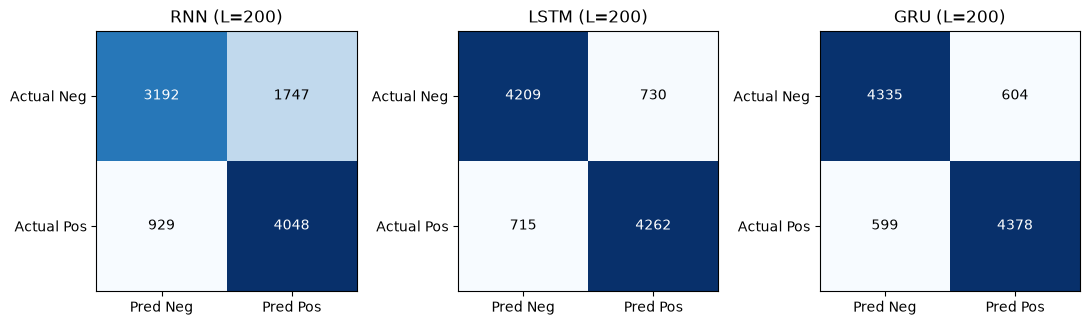

model có validation loss thấp nhất: GRU


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4)); y = test.label.values
for ax, (a, r) in zip(axes, runs200.items()):
    cm = confusion_matrix(y, (r["test_probs"]>=.5).astype(int)); ax.imshow(cm, cmap="Blues"); ax.set_title(f"{a} (L=200)")
    ax.set_xticks([0,1]); ax.set_yticks([0,1]); ax.set_xticklabels(["Pred Neg","Pred Pos"]); ax.set_yticklabels(["Actual Neg","Actual Pos"])
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
    tn, fp, fn, tp = cm.ravel(); log("confusion", a, "TN_FP_FN_TP", f"{tn},{fp},{fn},{tp}"); print(f"{a:5s} TN={tn} FP={fp} FN={fn} TP={tp}")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=130); plt.show()
bestname = min(runs200, key=lambda a: min(runs200[a]["hist"]["val_loss"])); print("model có validation loss thấp nhất:", bestname)

**Nhận xét confusion matrix:** RNN lỗi nhiều nhất và lệch rõ về một phía: FP = 1,747 so với FN = 929 (hay gọi review negative là positive). LSTM (FP 730, FN 715) và GRU (FP 604, FN 599) cân bằng hơn. Metric phản ánh điều này là **precision** của RNN (0.699) thấp hơn nhiều recall (0.813); accuracy gộp hai loại lỗi nên che mất sự lệch. Model có validation loss thấp nhất là GRU nên được dùng cho error analysis và application.

## Error analysis (model tốt nhất theo validation loss)

In [12]:
rb = runs200[bestname]; pb = (rb["test_probs"] >= .5).astype(int); tl_ = np.array([len(pp.tokenize(t)) for t in test.text]); T = test.text.values
rng = np.random.RandomState(SEED)
ok = rng.choice(np.where(pb == y)[0], 3, replace=False); fpi = np.where((pb==1)&(y==0))[0]; fni = np.where((pb==0)&(y==1))[0]
bad = list(rng.choice(fpi, 2, replace=False)) + list(rng.choice(fni, 2, replace=False)); lab = {0:"negative", 1:"positive"}
def show(i):
    w = T[i].split(); return " ".join(w[:55]) + (" [...] " + " ".join(w[-25:]) if len(w) > 80 else "")
print("== ĐÚNG =="); [print(f"[{lab[y[i]]} → {lab[pb[i]]}] p={rb['test_probs'][i]:.2f} len={tl_[i]}  {show(i)}\n") for i in ok]
print("== SAI =="); [print(f"[{lab[y[i]]} → {lab[pb[i]]}] p={rb['test_probs'][i]:.2f} len={tl_[i]}  {show(i)}\n") for i in bad]
err = pb != y
print("tỉ lệ lỗi theo độ dài: len<=200: %.3f (n=%d) | len>200: %.3f (n=%d)" % (err[tl_<=200].mean(), (tl_<=200).sum(), err[tl_>200].mean(), (tl_>200).sum()))
print("FP =", len(fpi), "| FN =", len(fni))
log("error_analysis", bestname, "err_rate_len<=200", round(float(err[tl_<=200].mean()),3)); log("error_analysis", bestname, "err_rate_len>200", round(float(err[tl_>200].mean()),3))

== ĐÚNG ==
[negative → negative] p=0.41 len=403  "Ordinary Decent Criminal" is sort of based on the exploits of Martin Cahill, already the subject of John Boorman's 1998 film "The General". Cahill had a rough upbringing in a slum area and graduated from petty crime to armed robbery with honours. He justified his criminal career by pointing out his poor background at every [...] of The People" self-image. Having Michael Lynch give up everything to avoid death in "ODC" is a cop-out ending to a weak and shallow movie.

[positive → positive] p=0.98 len=546  Time and time again, it seems that the comedic actors of Hollywood are surprising me with their talents as dramatic performers: first it was Robin Williams {'One Hour Photo (2002)'}, then it was Jim Carrey {'Eternal Sunshine (2004)' being one example}, then Will Ferrell {'Stranger than Fiction (2006)'} and now Adam Sandler. Yes, that's absolutely [...] sympathise, a hollow soul who, thanks to the companionship of an old friend, can fina

In [13]:
# KIỂM CHỨNG nguyên nhân lỗi: cùng model GRU (không train lại) đọc 3 phiên bản của review
#   (a) 200 token ĐẦU (đúng như lúc đánh giá), (b) 200 token CUỐI, (c) TOÀN BỘ review
mG = models200["GRU"]
def p_of(text, L):
    X, l = encode([text], L); return float(predict(mG, X, l)[0])
keys = {0: ["waste", "lousy", "unsatisfying", "forewarned"], 1: ["six", "love", "finale"], 2: ["splendid", "killing", "failed", "bodacious"], 3: ["trashy", "recommending", "effective", "compelling"]}
for k, i in enumerate(bad):
    toks = pp.tokenize(T[i]); n = len(toks)
    head, tail, full = p_of(T[i], 200), p_of(" ".join(toks[-200:]), 200), p_of(T[i], n)
    pos = {w: [j + 1 for j, t in enumerate(toks) if t == w][:5] for w in keys[k]}
    print(f"Sai {k+1}: nhãn thật = {lab[y[i]]}, {n} token | P(positive): 200 ĐẦU = {head:.3f} | 200 CUỐI = {tail:.3f} | TOÀN BỘ = {full:.3f}")
    print("        vị trí từ khóa (token thứ mấy):", {w: v for w, v in pos.items() if v})
long_idx = np.where(tl_ > 200)[0]; yl = y[long_idx]
ph = rb["test_probs"][long_idx]
Xt_, lt_ = encode([" ".join(pp.tokenize(T[i])[-200:]) for i in long_idx], 200); pt = predict(mG, Xt_, lt_)
pf = np.zeros(len(long_idx)); order = np.argsort(tl_[long_idx])
for s in range(0, len(order), 64):
    ii = order[s:s + 64]; Lc = int(min(tl_[long_idx][ii].max(), 2500))
    Xc, lc = encode([T[long_idx[j]] for j in ii], Lc); pf[ii] = predict(mG, Xc, lc)
acc_ = lambda p_: float(((p_ >= .5) == yl).mean())
wrong_ = (ph >= .5) != yl
print(f"\nReview dài (> 200 token, n = {len(long_idx)}): accuracy 200 ĐẦU = {acc_(ph):.4f} | 200 CUỐI = {acc_(pt):.4f} | TOÀN BỘ = {acc_(pf):.4f}")
print(f"Trong {wrong_.sum()} review dài sai khi chỉ đọc 200 đầu: được sửa đúng khi đọc 200 cuối = {((pt >= .5) == yl)[wrong_].mean():.3f} | khi đọc toàn bộ = {((pf >= .5) == yl)[wrong_].mean():.3f}")
print(f"Trong {(~wrong_).sum()} review dài đang đúng: thành sai khi đọc 200 cuối = {((pt >= .5) != yl)[~wrong_].mean():.3f} | khi đọc toàn bộ = {((pf >= .5) != yl)[~wrong_].mean():.3f}")
for a_, b_ in [(0, 100), (100, 200), (200, 300), (300, 500), (500, 3000)]:
    sel = np.where((tl_ > a_) & (tl_ <= b_))[0]
    print(f"  độ dài ({a_},{b_}]: n = {len(sel):5d} | tỉ lệ lỗi (đọc 200 đầu) = {((rb['test_probs'][sel] >= .5) != y[sel]).mean():.3f}")
log("verify_truncation", "GRU_long_reviews", "acc_first200", round(acc_(ph), 4)); log("verify_truncation", "GRU_long_reviews", "acc_last200", round(acc_(pt), 4)); log("verify_truncation", "GRU_long_reviews", "acc_full", round(acc_(pf), 4))

Sai 1: nhãn thật = negative, 438 token | P(positive): 200 ĐẦU = 0.680 | 200 CUỐI = 0.013 | TOÀN BỘ = 0.019
        vị trí từ khóa (token thứ mấy): {'waste': [420, 425], 'lousy': [436], 'unsatisfying': [11], 'forewarned': [429]}
Sai 2: nhãn thật = negative, 394 token | P(positive): 200 ĐẦU = 0.734 | 200 CUỐI = 0.980 | TOÀN BỘ = 0.986
        vị trí từ khóa (token thứ mấy): {'six': [6], 'love': [303, 374], 'finale': [394]}


Sai 3: nhãn thật = positive, 465 token | P(positive): 200 ĐẦU = 0.130 | 200 CUỐI = 0.343 | TOÀN BỘ = 0.124
        vị trí từ khóa (token thứ mấy): {'splendid': [6], 'killing': [41], 'failed': [457], 'bodacious': [10]}


Sai 4: nhãn thật = positive, 238 token | P(positive): 200 ĐẦU = 0.215 | 200 CUỐI = 0.880 | TOÀN BỘ = 0.593
        vị trí từ khóa (token thứ mấy): {'trashy': [50], 'recommending': [230], 'effective': [217], 'compelling': [218]}



Review dài (> 200 token, n = 4015): accuracy 200 ĐẦU = 0.8496 | 200 CUỐI = 0.8869 | TOÀN BỘ = 0.9088
Trong 604 review dài sai khi chỉ đọc 200 đầu: được sửa đúng khi đọc 200 cuối = 0.680 | khi đọc toàn bộ = 0.632
Trong 3411 review dài đang đúng: thành sai khi đọc 200 cuối = 0.077 | khi đọc toàn bộ = 0.042
  độ dài (0,100]: n =  1268 | tỉ lệ lỗi (đọc 200 đầu) = 0.095
  độ dài (100,200]: n =  4633 | tỉ lệ lỗi (đọc 200 đầu) = 0.103
  độ dài (200,300]: n =  1824 | tỉ lệ lỗi (đọc 200 đầu) = 0.111
  độ dài (300,500]: n =  1415 | tỉ lệ lỗi (đọc 200 đầu) = 0.186
  độ dài (500,3000]: n =   776 | tỉ lệ lỗi (đọc 200 đầu) = 0.179


### Phân tích lỗi (model GRU, max_length = 200) và kiểm chứng
Giả thuyết ban đầu: nhiều lỗi do **truncation** (ta giữ 200 token đầu, nên kết luận ở cuối review bị cắt). Cách kiểm chứng ở ô code ngay trên: cho **cùng một model** đọc 200 token đầu / 200 token cuối / toàn bộ review và xem dự đoán có đổi không (không train lại).

| # | True → Pred | Nội dung (rút gọn) | Giả thuyết | Kiểm chứng (P(positive): đầu → cuối → toàn bộ) | Kết luận |
|---|---|---|---|---|---|
| Đúng 1 | negative → negative (p=0.41) | "Ordinary Decent Criminal ... a cop-out ending to a weak and shallow movie" (403 token) | — | — | Đúng nhưng sát ngưỡng |
| Đúng 2 | positive → positive (p=0.98) | "comedic actors ... surprising me with their talents ..." (546 token) | — | — | Nhiều từ khen rõ ở đầu |
| Đúng 3 | negative → negative (p=0.06) | "What a terrible movie! ... nonsensical ... shallow" (173 token) | — | — | Từ chê mạnh, review ngắn |
| Sai 1 | negative → positive | "highly unsatisfying ... 'A WASTE OF MONEY, AND A WASTE OF TIME' ... lousy script writing." (438 token) | truncation + contrast | Từ chê *waste, forewarned, lousy* ở token 420–436 (> 200). 0.680 → 0.013 → 0.019 | **Xác nhận: lỗi do truncation** (đọc phần cuối/toàn bộ thì đúng) |
| Sai 2 | negative → positive | "I give the show a six ... I love the show ... can't wait to see the series finale" (394 token) | nhãn mơ hồ/nhiễu (không phải truncation) | 0.734 → 0.980 → 0.986: đọc thêm lại càng tự tin positive (*love* ở token 303, 374) | **Không do truncation.** Nội dung nghiêng hẳn về khen; phù hợp với giả thuyết nhãn mơ hồ (điểm 6/10), nhưng không chứng minh được nhãn nhiễu |
| Sai 3 | positive → negative | "a splendid showcase for Mandy's bodacious bod ... character goes around killing people ... skin flicks that failed" (465 token) | sarcasm / domain-specific | 0.130 → 0.343 → 0.124: đọc toàn bộ vẫn negative (*failed* ở token 457 nhưng không giúp) | **Không do truncation** (giả thuyết truncation của mình bị bác bỏ). Giọng điệu mỉa mai/mơ hồ vẫn chỉ là phỏng đoán, chưa kiểm chứng được |
| Sai 4 | positive → negative | "attacked ... cannibalistic monster ... trashy ... [but] ... no hesitation in recommending" (238 token) | truncation + contrast | Lời khen *effective, compelling, recommending* ở token 217–230 (> 200). 0.215 → 0.880 → 0.593 | **Xác nhận: lỗi do truncation** (đọc toàn bộ vẫn sát ngưỡng vì đoạn tóm tắt tiêu cực ở đầu) |

**Kiểm chứng trên toàn bộ 4,015 review dài** (cùng model, không train lại): accuracy khi chỉ đọc 200 token đầu là **0.8496**, 200 token cuối **0.8869**, toàn bộ review **0.9088**. Trong 604 review dài bị sai, 63.2% được sửa đúng khi đọc toàn bộ (68.0% khi đọc 200 cuối); ngược lại 4.2% review đang đúng lại thành sai. Tỉ lệ lỗi theo độ dài: ≤ 200 token khoảng 9.5–10.3%, 200–300 token 11.1%, 300–500 token 18.6%, > 500 token 17.9%. Đọc toàn bộ đưa lỗi của review dài (9.1%) về ngang review ngắn (10.2%), nên phần lớn lỗi *thừa* của review dài **do truncation**, không phải do GRU không hiểu câu. Hạn chế: truncation chỉ giải thích phần nào (2/4 mẫu, ~63% lỗi review dài); phần còn lại là nhãn mơ hồ, mỉa mai, tương phản. Model được train với cách cắt 200 token đầu nhưng vẫn nhận được chuỗi dài hơn, kết quả toàn bộ review chỉ là ước lượng.

## Application — sentiment classifier hoàn chỉnh (+ giải thích bằng occlusion)
Chọn model theo validation loss. Để xem token nào ảnh hưởng, bỏ từng token và đo thay đổi P(positive) (leave-one-token-out): giá trị lớn nghĩa là token đó quan trọng với prediction này (chỉ là quan sát thực nghiệm, không phải giải thích cơ chế).

In [14]:
mbest = models200[bestname]
def classify(text, L=200, top=5):
    toks = pp.tokenize(text); p = prob(mbest, text, L); drops = []
    for i in range(len(toks[:L])):
        q = prob(mbest, " ".join(toks[:i] + toks[i+1:]), L); drops.append((toks[i], round(p - q, 3)))
    top_ = sorted(drops, key=lambda t: -abs(t[1]))[:top]
    return p, top_
longrev = test.text[np.where(tl_ > 250)[0][0]]
cases = [("ngắn", "I really enjoyed this movie."), ("phủ định", "I did not like this movie at all."),
         ("tương phản", "I thought the movie would be terrible, but it was surprisingly good."),
         ("tương phản 2", "I expected the movie to be bad, but it was actually wonderful."),
         ("dài (review thật, %d token)" % tl_[np.where(tl_ > 250)[0][0]], longrev)]
for name, s in cases:
    p, top_ = classify(s)
    print(f"[{name}] P(positive) = {p:.3f} → {'Positive' if p >= .5 else 'Negative'} | token ảnh hưởng nhất (Δp khi bỏ token): {top_}")
    print("   ", " ".join(s.split()[:30]) + (" ..." if len(s.split()) > 30 else ""), "\n")

[ngắn] P(positive) = 0.991 → Positive | token ảnh hưởng nhất (Δp khi bỏ token): [('enjoyed', 0.279), ('really', 0.022), ('movie', 0.016), ('i', 0.003), ('this', 0.003)]
    I really enjoyed this movie. 

[phủ định] P(positive) = 0.086 → Negative | token ảnh hưởng nhất (Δp khi bỏ token): [('at', -0.095), ('not', -0.083), ('did', -0.043), ('this', -0.031), ('all', -0.025)]
    I did not like this movie at all. 

[tương phản] P(positive) = 0.455 → Negative | token ảnh hưởng nhất (Δp khi bỏ token): [('terrible', -0.411), ('surprisingly', 0.195), ('but', 0.191), ('good', 0.186), ('be', 0.133)]
    I thought the movie would be terrible, but it was surprisingly good. 

[tương phản 2] P(positive) = 0.263 → Negative | token ảnh hưởng nhất (Δp khi bỏ token): [('bad', -0.307), ('expected', -0.236), ('wonderful', 0.131), ('i', 0.088), ('but', 0.081)]
    I expected the movie to be bad, but it was actually wonderful. 



[dài (review thật, 276 token)] P(positive) = 0.850 → Positive | token ảnh hưởng nhất (Δp khi bỏ token): [('hilarious', 0.314), ('only', 0.175), ('good', 0.147), ('makes', 0.139), ('great', 0.131)]
    Walter Matthau and George Burns were a famous vaudeville comedy act, Lewis and Clark, who haven't spoken in over 10 years. Burns retired and Matthau took it personally and has ... 



**Giải thích bằng occlusion (Δp khi bỏ token):** "I really enjoyed this movie" → Positive (0.991), token quan trọng nhất là *enjoyed* (+0.279). "I did not like this movie at all" → Negative (0.086): *not* (−0.083) và *at/all* ảnh hưởng, tức model nhận ra phủ định. Hai câu **tương phản** đều bị dự đoán sai: "I thought the movie would be terrible, but it was surprisingly good" → 0.455 (Negative) vì *terrible* kéo xuống mạnh nhất (−0.411) dù *surprisingly, but, good* kéo lên; "I expected the movie to be bad, but it was actually wonderful" → 0.263 vì *bad* (−0.307) và *expected* (−0.236). Cho thấy model chưa xử lý tốt cấu trúc "kỳ vọng tiêu cực nhưng kết quả tích cực": từ chê ở đầu vẫn chi phối. Review dài thật (276 token) → Positive (0.850), dựa vào *hilarious, good, great*. Đây là quan sát thực nghiệm trên vài câu, không phải giải thích cơ chế.

## Lưu kết quả

In [15]:
with open("results.csv", "w", newline="", encoding="utf8") as f:
    wr = csv.writer(f); wr.writerow(["experiment","config","metric","value"]); wr.writerows(RESULTS)
print(len(RESULTS), "rows → results.csv")

78 rows → results.csv
